# 03 · Risk model: how close is each truck to a Component X repair?

**Question:** given a truck's readouts so far, what are the probabilities that its repair falls in
each urgency window (class 0 = none within 48 steps, 1 = [24, 48), 2 = [12, 24), 3 = [6, 12),
4 = [0, 6))? And does acting on those probabilities beat the baselines from notebook 02?

| Bar to beat (validation, cost per 1,000 trucks) | |
|---|---|
| Call every truck in now | 9,823 |
| **Fixed-age rule, baseline (b)** | **9,702** (CV 10,028) |
| Age bands, any direction (validation-tuned) | 8,109 (CV 8,354) |

Data: SCANIA Component X dataset, Swedish National Data Service,
https://doi.org/10.5878/bnh5-ka77, CC BY 4.0.

Ground rules (CLAUDE.md):
- **Unit = vehicle.** Training CV folds are grouped by vehicle; validation is one row per vehicle.
- **Training** fits the models and chooses hyperparameters. **Validation** is used for
  recalibration and for comparing models, always *cross-fitted* (anything tuned on some
  validation trucks is scored on others). **Test is not used here**; it is touched once, in notebook 04.
- Features use only readouts at or before the prediction point (`sql/03_features.sql`, tested).
- Variables are anonymized: "counter 427", "histogram 397, bin 12", with no physical meaning implied.

In [1]:
import json
import sys
import time
from pathlib import Path

import duckdb
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
import shap
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, log_loss, recall_score, roc_auc_score
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import viz
from costs import ACTIONS, CLASSES, COST, cost_per_1000, expected_cost_decision
from make_features_sql import FEATURES
from risk_model import (AGE_IDX, INPUTS, SPEC_COLS, apply_calibrator, due_log_odds, fit_calibrator,
                        model_matrix, pretty, signed_log, spec_levels_from, sqrt_balanced_class_weights)

viz.apply_style()
FIGS = ROOT / "docs" / "figures"
PROCESSED = ROOT / "data" / "processed"
con = duckdb.connect(str(ROOT / "data" / "pdm.duckdb"), read_only=True)


def q(sql, *params):
    return con.execute(sql, list(params)).df()


SEED = 2024
K = 5   # prediction points per training vehicle
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_columns", 30)

## 1. Training prediction points that mimic validation

**Choice (before the code).** A validation truck is scored once, at a random cut point, so every
truck counts equally. Training has a label for every readout, but using all 1.1M readouts as
equal rows would let long-lived trucks with many readouts dominate.

- Each training vehicle contributes **up to 5 readouts drawn at random** (hash-ordered,
  reproducible) from those with a known class, and each gets **weight 1/k** (k = the vehicle's
  number of drawn points). Every vehicle therefore counts once, as in validation, and drawing
  several points per vehicle instead of one reduces the variance of the sample.
- Readouts with an unknown class (censored, within 48 steps of the end of observation) are
  dropped, as CLAUDE.md specifies.
- The class mix will **not** match validation's (notebook 01: random training cuts have too much
  class 1 and too little class 4), and validation's age pattern runs against training's
  (notebook 02). That is handled after training, by recalibrating the probabilities on validation,
  not by distorting the training sample.

In [2]:
cols = ", ".join(f'"{c}"' for c in INPUTS)
train = q(f'''
    SELECT vehicle_id, class_label, {cols},
           count(*) OVER (PARTITION BY vehicle_id) AS points_in_vehicle
    FROM (SELECT * FROM train_features WHERE class_label IS NOT NULL
          QUALIFY row_number() OVER (PARTITION BY vehicle_id
                                     ORDER BY hash(vehicle_id, time_step, {SEED})) <= {K})
''')
train["w_vehicle"] = 1.0 / train["points_in_vehicle"]
val = q(f"SELECT vehicle_id, class_label, {cols} FROM vehicle_features WHERE split = 'validation'")
assert len(val) == 5046 and val.vehicle_id.is_unique

y_tr, w_tr, g_tr = train.class_label.to_numpy(), train.w_vehicle.to_numpy(), train.vehicle_id.to_numpy()
y_val = val.class_label.to_numpy()
mix = pd.DataFrame({
    "training points (vehicle-weighted)": pd.Series(w_tr).groupby(y_tr).sum() / w_tr.sum(),
    "validation": pd.Series(y_val).value_counts(normalize=True).sort_index(),
})
print(f"training points: {len(train):,} from {train.vehicle_id.nunique():,} vehicles; "
      f"validation trucks: {len(val):,}")
(100 * mix).round(2).rename(columns=lambda c: f"{c}, %")

training points: 117,039 from 23,549 vehicles; validation trucks: 5,046


,"training points (vehicle-weighted), %","validation, %"
0,97.3100,97.3000
1,1.3100,0.3200
2,0.6600,0.2800
3,0.3100,0.5900
4,0.3900,1.5100


**Interpretation.** 117,039 training points from 23,549 vehicles (one vehicle has no readout with a known class). Vehicle-weighted, the share of class 0 matches validation almost exactly (97.31% vs 97.30%), but the urgent classes are mixed differently: training has 4× validation's share of class 1 and only a quarter of its share of class 4. The model learns the risk structure from training; the class priors are corrected on validation in section 4.

## 2. Inputs and the two models

**Inputs (88):** the 80 per-readout features from `sql/03_features.sql` (including `time_step`)
plus Spec_0 … Spec_7. Spec categories with fewer than 200 training vehicles are pooled into
"Other" (as in notebook 02); a validation category not seen in training also maps to "Other".

**(a) Multinomial logistic regression**, the interpretable model:
- Numeric features get a **sign-preserving log** first (the counters have very long right tails,
  which a linear model handles badly), then median imputation **with a missing-indicator column**
  (missing values come in blocks, notebook 01), then standardization.
- Specs are one-hot encoded.
- L2 regularization strength `C` is chosen by CV.

**(b) `HistGradientBoostingClassifier`**, multiclass gradient boosting:
- Raw features (trees don't need transforms) with **native NaN handling**; specs as native
  categorical features.
- Tree size and learning rate are chosen by CV.

**Class weights (both models):** `sqrt(N / (5·N_k))` on vehicle-weighted counts. Class 3 is about
0.3% of the points, so full "balanced" weights would multiply it about 60×. The square root
(about 8×) still makes the models learn the rare urgent classes, while distorting the
probabilities less. Any remaining distortion of class priors is removed by recalibration (section 4).

In [3]:
spec_levels = spec_levels_from(train)
X_tr = model_matrix(train, spec_levels)
X_val = model_matrix(val, spec_levels)
n_num, n_spec = len(FEATURES), len(SPEC_COLS)
cat_mask = np.r_[np.zeros(n_num, bool), np.ones(n_spec, bool)]
cw = sqrt_balanced_class_weights(y_tr, w_tr)
sw_tr = w_tr * np.vectorize(cw.get)(y_tr)
print("class weights:", {k: round(v, 2) for k, v in cw.items()})
print("spec groups after pooling:", {c: len(v) for c, v in spec_levels.items()})


def make_logistic(C):
    pre = ColumnTransformer([
        ("num", make_pipeline(FunctionTransformer(signed_log, feature_names_out="one-to-one"),
                              SimpleImputer(strategy="median", add_indicator=True), StandardScaler()),
         list(range(n_num))),
        ("spec", OneHotEncoder(handle_unknown="ignore"), list(range(n_num, n_num + n_spec))),
    ])
    return make_pipeline(pre, LogisticRegression(C=C, max_iter=2000))


def make_hgb(leaves, lr, iters):
    return HistGradientBoostingClassifier(
        max_leaf_nodes=leaves, learning_rate=lr, max_iter=iters, min_samples_leaf=200,
        l2_regularization=1.0, categorical_features=cat_mask, early_stopping=False, random_state=SEED)


def fit(model, X, y, sw):
    if hasattr(model, "steps"):
        return model.fit(X, y, logisticregression__sample_weight=sw)
    return model.fit(X, y, sample_weight=sw)

class weights: {0: 0.45, 1: 3.9, 2: 5.48, 3: 7.99, 4: 7.12}
spec groups after pooling: {'Spec_0': 3, 'Spec_1': 17, 'Spec_2': 9, 'Spec_3': 5, 'Spec_4': 3, 'Spec_5': 5, 'Spec_6': 7, 'Spec_7': 10}


## 3. Hyperparameters: vehicle-grouped CV on training

**Choice.** 3-fold `GroupKFold` by `vehicle_id`, so no truck has points on both sides of a split.
The score is the **vehicle-weighted log-loss** on the held-out fold. Log-loss is a proper scoring
rule: it rewards honest probabilities, which is what the expected-cost rule consumes. The
challenge cost is *not* used here, because the training class mix differs from validation's and
cost depends on that mix. The grids are kept small because one boosting fit takes minutes.
Validation is not involved in this step.

In [4]:
LR_GRID = [0.01, 0.1, 1.0]
HGB_GRID = [(15, 0.1, 150), (31, 0.1, 150), (15, 0.05, 300)]
folds = list(GroupKFold(n_splits=3).split(X_tr, y_tr, g_tr))
rows = []
for name, grid, build in [("logistic", LR_GRID, lambda c: make_logistic(c)),
                          ("hist_gb", HGB_GRID, lambda c: make_hgb(*c))]:
    for config in grid:
        t0, losses, aucs = time.time(), [], []
        for tr, te in folds:
            m = fit(build(config), X_tr[tr], y_tr[tr], sw_tr[tr])
            p = m.predict_proba(X_tr[te])
            losses.append(log_loss(y_tr[te], p, sample_weight=w_tr[te], labels=CLASSES))
            aucs.append(roc_auc_score(y_tr[te] > 0, 1 - p[:, 0], sample_weight=w_tr[te]))
        rows.append({"model": name, "config": str(config), "cv_log_loss": np.mean(losses),
                     "cv_log_loss_sd": np.std(losses), "cv_auc_due": np.mean(aucs),
                     "seconds": time.time() - t0})
cv = pd.DataFrame(rows)
best = {m: cv[cv.model == m].sort_values("cv_log_loss").iloc[0] for m in ["logistic", "hist_gb"]}
print({m: b.config for m, b in best.items()})
cv

{'logistic': '0.1', 'hist_gb': '(31, 0.1, 150)'}


,model,config,cv_log_loss,cv_log_loss_sd,cv_auc_due,seconds
0,logistic,0.01,0.2868,0.0003,0.8162,28.0950
1,logistic,0.1,0.2853,0.0007,0.8175,42.4972
2,logistic,1.0,0.2865,0.0006,0.8158,68.4591
3,hist_gb,"(15, 0.1, 150)",0.1843,0.0018,0.8227,188.0632
4,hist_gb,"(31, 0.1, 150)",0.1511,0.0020,0.8216,237.5499
5,hist_gb,"(15, 0.05, 300)",0.1836,0.0019,0.8252,263.9840


**Interpretation.** For the logistic model the regularization strength hardly matters (log-loss 0.2853–0.2868); C = 0.1 is chosen. For gradient boosting, larger trees fit clearly better (log-loss 0.151 with 31 leaves vs 0.184 with 15), so 31 leaves, learning rate 0.1 and 150 iterations are chosen. Both families separate due from not-due trucks about equally well within training (AUC 0.82). Gradient boosting's much lower log-loss says its *probabilities* are sharper, which matters for the expected-cost rule. The training-CV AUC will not carry over in full to validation, whose age pattern differs (notebook 02).

## 4. Final models, raw validation probabilities, and recalibration

Both models are refitted on **all** training points with their chosen hyperparameters and
score the 5,046 validation trucks at their last readout.

**Recalibration (choice before the code).** Raw probabilities are expected to be off on
validation for three known reasons:
1. the class weights,
2. the class-mix difference between random training cuts and validation (notebook 01),
3. validation's age pattern running *against* training's (notebook 02).

Two small calibrators are fitted on the raw log-probabilities by maximum likelihood (with a tiny
ridge penalty):
- **calibrated**: a temperature *T* and one bias per urgent class:
  $z_k = \log p_k / T + b_k$, softmax (5 parameters). It fixes over/under-confidence and
  class priors, and keeps the model's ranking.
- **calibrated + age**: also adds $a_1 u + a_2 u^2$ to the logits of classes 1–4, with
  $u = (\text{age} - 170)/100$ (7 parameters). It can bend the risk-by-age curve towards what
  validation shows. The quadratic allows the rise-then-fall seen in notebook 02.

**Honest evaluation.** The calibrators are fitted on validation, so they are **cross-fitted**:
5-fold stratified splits of validation trucks, repeated 5 times. Each truck's calibrated
probability is the average of the 5 calibrators that did *not* see it. Every validation number
below is therefore out-of-sample with respect to the calibration. Final calibrators, fitted on
all validation trucks, are saved for scoring test in notebook 04.

In [5]:
t0 = time.time()
final = {"logistic": fit(make_logistic(float(best["logistic"].config)), X_tr, y_tr, sw_tr),
         "hist_gb": fit(make_hgb(*eval(best["hist_gb"].config)), X_tr, y_tr, sw_tr)}
raw = {m: final[m].predict_proba(X_val) for m in final}
age_val = X_val[:, AGE_IDX]
print(f"final fits: {time.time() - t0:,.0f} s")


def crossfit(logp, age, y, age_terms, repeats=5, n_folds=5):
    out = np.zeros_like(logp)
    for r in range(repeats):
        for a, b in StratifiedKFold(n_folds, shuffle=True, random_state=r).split(logp, y):
            params = fit_calibrator(logp[a], age[a], y[a], age_terms)
            out[b] += apply_calibrator(logp[b], age[b], params, age_terms)
    return out / repeats


probs, calibrators = {}, {}
for m, p in raw.items():
    logp = np.log(np.clip(p, 1e-9, 1))
    probs[(m, "raw")] = p
    for variant, age_terms in [("calibrated", False), ("calibrated + age", True)]:
        probs[(m, variant)] = crossfit(logp, age_val, y_val, age_terms)
        calibrators[(m, variant)] = fit_calibrator(logp, age_val, y_val, age_terms).tolist()
for key, params in calibrators.items():
    print(key, "T =", round(float(np.exp(params[0])), 2), "biases =", np.round(params[1:5], 2),
          "age terms =", np.round(params[5:], 2) if len(params) > 5 else "-")

final fits: 110 s


('logistic', 'calibrated') T = 1.23 biases = [-3.45 -3.39 -3.26 -2.52] age terms = -
('logistic', 'calibrated + age') T = 1.1 biases = [-2.92 -2.78 -2.63 -1.82] age terms = [-0.54 -0.92]
('hist_gb', 'calibrated') T = 1.11 biases = [-2.75 -2.16 -1.29 -0.45] age terms = -
('hist_gb', 'calibrated + age') T = 1.19 biases = [-2.54 -1.93 -1.1  -0.27] age terms = [-0.11 -0.67]


## 5. Model comparison on validation

For every model × probability variant, two ways to turn probabilities into an action:
- **argmax**: the most likely class. It ignores costs, so with 97% class 0 it will mostly say "no action".
- **expected cost**: the action with the lowest $\sum_k P(k)\,\text{COST}[k][\text{action}]$
  (`src/costs.py`). This is the decision rule notebook 04 builds on.

Reported per row: challenge cost per 1,000 trucks, macro-F1 and recall per class (how often each
true class gets exactly the right action), call-ins per 1,000 trucks, and how many of the 136
trucks with a repair due got *some* action. Log-loss and the AUC of P(due) describe the
probabilities themselves and are the same for both decision rules.

In [6]:
baselines = pd.read_csv(PROCESSED / "baselines_validation.csv").set_index("policy")
rows = []
for (m, variant), p in probs.items():
    ll = log_loss(y_val, p, labels=CLASSES)
    auc = roc_auc_score(y_val > 0, 1 - p[:, 0])
    for rule, pred in [("argmax", p.argmax(axis=1)), ("expected cost", expected_cost_decision(p))]:
        rec = recall_score(y_val, pred, labels=CLASSES, average=None, zero_division=0)
        rows.append({
            "model": m, "probabilities": variant, "decision": rule,
            "cost_per_1000": cost_per_1000(y_val, pred),
            "macro_F1": f1_score(y_val, pred, labels=CLASSES, average="macro", zero_division=0),
            **{f"recall_{k}": r for k, r in zip(CLASSES, rec)},
            "call_ins_per_1000": 1000 * (pred > 0).mean(),
            "due_trucks_flagged": int(((pred > 0) & (y_val > 0)).sum()),
            "log_loss": ll, "auc_due": auc,
        })
comparison = pd.DataFrame(rows)
pd.set_option("display.width", 250)
comparison.sort_values("cost_per_1000").round(
    {"cost_per_1000": 0, "call_ins_per_1000": 0, "macro_F1": 3, **{f"recall_{k}": 2 for k in CLASSES},
     "log_loss": 4, "auc_due": 3}).reset_index(drop=True)

,model,probabilities,decision,cost_per_1000,macro_F1,recall_0,recall_1,recall_2,recall_3,recall_4,call_ins_per_1000,due_trucks_flagged,log_loss,auc_due
0,hist_gb,calibrated + age,expected cost,"6,538.0000",0.1620,0.6100,0.0000,0.0000,0.0000,0.7800,404.0000,102,0.1569,0.7420
1,logistic,calibrated + age,expected cost,"7,037.0000",0.1470,0.5200,0.0000,0.0000,0.0000,0.8400,487.0000,107,0.1615,0.7180
2,hist_gb,calibrated,expected cost,"7,294.0000",0.1540,0.5700,0.0000,0.0000,0.0000,0.7100,440.0000,99,0.1605,0.7170
3,logistic,calibrated,expected cost,"7,892.0000",0.1220,0.4000,0.0000,0.0000,0.0000,0.8700,609.0000,111,0.1667,0.6450
4,hist_gb,raw,expected cost,"8,955.0000",0.0830,0.2200,0.0000,0.0700,0.1300,0.6800,782.0000,126,0.2848,0.7080
5,logistic,raw,expected cost,"9,391.0000",0.0220,0.0400,0.0000,0.0000,0.0000,1.0000,961.0000,136,0.6503,0.6460
6,logistic,raw,argmax,"10,869.0000",0.2010,0.9200,0.0000,0.0000,0.0300,0.0500,81.0000,21,0.6503,0.6460
7,hist_gb,raw,argmax,"11,067.0000",0.2080,0.9900,0.0600,0.0000,0.0000,0.0100,11.0000,12,0.2848,0.7080
8,hist_gb,calibrated,argmax,"11,286.0000",0.2020,1.0000,0.0000,0.0000,0.0000,0.0100,1.0000,1,0.1605,0.7170
9,logistic,calibrated,argmax,"11,288.0000",0.2020,1.0000,0.0000,0.0000,0.0000,0.0100,1.0000,1,0.1667,0.6450


In [7]:
cand = comparison[comparison.decision == "expected cost"].sort_values(["cost_per_1000", "model"])
chosen = cand.iloc[0]
CHOSEN = (chosen.model, chosen.probabilities)
p_best = probs[CHOSEN]
pred_best = expected_cost_decision(p_best)
print(f"chosen: {CHOSEN[0]} with '{CHOSEN[1]}' probabilities + expected-cost rule -> "
      f"{chosen.cost_per_1000:,.0f} per 1,000 trucks")
print(f"vs call everyone in 9,823 | fixed-age rule 9,702 (CV 10,028) | age bands 8,109 (CV 8,354)")

chosen: hist_gb with 'calibrated + age' probabilities + expected-cost rule -> 6,538 per 1,000 trucks
vs call everyone in 9,823 | fixed-age rule 9,702 (CV 10,028) | age bands 8,109 (CV 8,354)


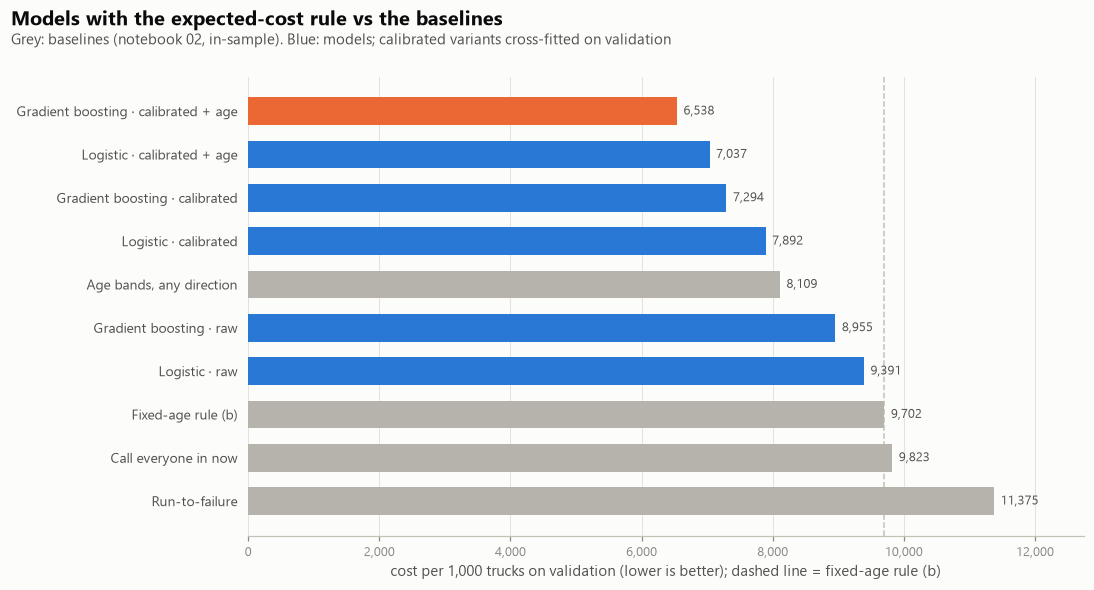

In [8]:
fig, ax = plt.subplots(figsize=(10, 5.2))
show = cand.copy()
show["label"] = show.model.map({"logistic": "Logistic", "hist_gb": "Gradient boosting"}) + " · " + show.probabilities
base = pd.DataFrame({"label": ["Run-to-failure", "Call everyone in now", "Fixed-age rule (b)", "Age bands, any direction"],
                     "cost_per_1000": [11375, 9823, 9702, 8109]})
allp = pd.concat([base.assign(kind="baseline"), show[["label", "cost_per_1000"]].assign(kind="model")])
allp = allp.sort_values("cost_per_1000", ascending=False).reset_index(drop=True)
colors = [viz.GREY_LIGHT if k == "baseline" else viz.BLUE for k in allp.kind]
best_i = allp.index[allp.label == show.iloc[0].label][0]
colors[best_i] = viz.ORANGE
ax.barh(range(len(allp)), allp.cost_per_1000, color=colors, height=0.64)
for i, v in enumerate(allp.cost_per_1000):
    ax.text(v + 100, i, f"{v:,.0f}", va="center", fontsize=8.5, color=viz.INK2)
ax.set_yticks(range(len(allp)), allp.label)
ax.tick_params(axis="y", colors=viz.INK2, labelsize=9)
ax.axvline(9702, color=viz.AXIS, lw=1, ls="--", zorder=0)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(0, allp.cost_per_1000.max() * 1.12)
ax.set_xlabel("cost per 1,000 trucks on validation (lower is better); dashed line = fixed-age rule (b)")
viz.suptitle(fig, "Models with the expected-cost rule vs the baselines",
             "Grey: baselines (notebook 02, in-sample). Blue: models; calibrated variants cross-fitted on validation")
fig.tight_layout()
viz.save(fig, "03_model_comparison", FIGS)
plt.show()

**Interpretation.**

- **The best policy is gradient boosting + age-aware calibration + the expected-cost rule: 6,538 per 1,000 trucks** (calibration cross-fitted). That is 33% below calling everyone in (9,823) and below the fixed-age rule, baseline (b) (9,702), and 19% below the age-band bar (8,109; 22% below its CV estimate of 8,354).
- **Calibration is the biggest lever.** Gradient boosting goes from 8,955 (raw) to 7,294 (calibrated) to 6,538 (calibrated + age). Every calibrated model beats every baseline, while the raw models only just beat calling everyone in.
- **Gradient boosting beats logistic regression in every variant**, by 500–600 per 1,000 trucks.
- **Argmax is worse than calling everyone in** (10,869–11,387): the most likely class is almost always 0, so it hardly ever calls a truck in. Argmax also has the *highest* macro-F1 (about 0.20), which shows why F1 is the wrong yardstick when a miss costs 20–50× a false alarm.
- **The policy is in practice a yes/no call-in decision.** Recall for classes 1–3 is 0: due trucks get "Call in now" or nothing, because calling in a class 1–3 truck now costs only 7–9, while waiting risks 200–500. This fits notebook 01: the readouts show *which* trucks are at risk far better than *when*.
- **Caveat:** the winner was picked from six candidates on validation, which flatters it a little. Hyperparameters came from training CV and calibration is cross-fitted, but the final verdict is the one-time test evaluation in notebook 04.

## 6. Calibration check

CLAUDE.md requires checking calibration before probabilities feed the expected-cost rule. Two views
of the chosen model's **P(repair due within 48 steps) = 1 − P(class 0)**:
1. **Reliability:** validation trucks in 8 bins of predicted risk (equal counts); predicted mean
   vs observed share due. A calibrated model sits on the diagonal.
2. **By age:** observed vs predicted share due per age band, the problem notebook 02 flagged.

Both compare the raw probabilities with the chosen (cross-fitted) ones.

In [9]:
raw_best = raw[CHOSEN[0]]
due = (y_val > 0).astype(int)
cal = pd.DataFrame({"due": due, "age": age_val, "raw": 1 - raw_best[:, 0], "chosen": 1 - p_best[:, 0]})
AGE_BINS = [0, 100, 150, 200, 250, 300, 500]
cal["age_band"] = pd.cut(cal.age, AGE_BINS, right=False)
by_age = cal.groupby("age_band", observed=True).agg(trucks=("due", "size"), observed=("due", "mean"),
                                                    predicted_raw=("raw", "mean"), predicted_chosen=("chosen", "mean"))
summary = pd.DataFrame({
    "mean predicted": [cal.raw.mean(), cal.chosen.mean()],
    "observed share due": [due.mean()] * 2,
    "Brier (due)": [((cal.raw - due) ** 2).mean(), ((cal.chosen - due) ** 2).mean()],
}, index=["raw", f"chosen ({CHOSEN[1]})"])
display(summary)
by_age

,mean predicted,observed share due,Brier (due)
raw,0.1545,0.0270,0.0570
chosen (calibrated + age),0.0387,0.0270,0.0262


,trucks,observed,predicted_raw,predicted_chosen
age_band,,,,
"[0, 100)",998,0.0230,0.0982,0.0240
"[100, 150)",1083,0.0416,0.1774,0.0605
"[150, 200)",824,0.0303,0.1849,0.0642
"[200, 250)",722,0.0402,0.1475,0.0424
"[250, 300)",688,0.0087,0.1467,0.0215
"[300, 500)",731,0.0109,0.1773,0.0100


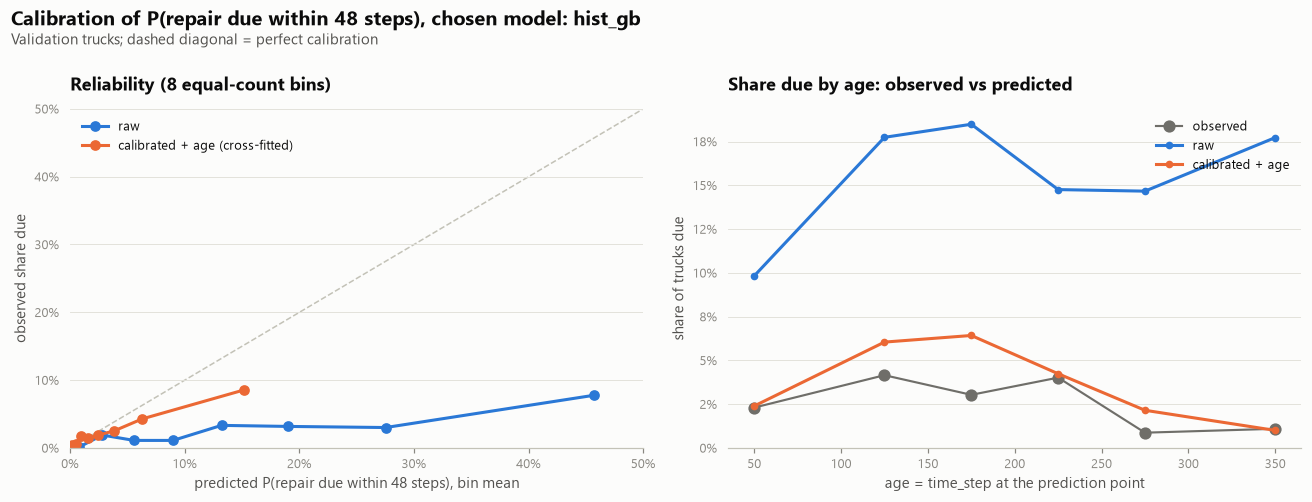

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
for col, color, label in [("raw", viz.BLUE, "raw"), ("chosen", viz.ORANGE, f"{CHOSEN[1]} (cross-fitted)")]:
    b = pd.qcut(cal[col].rank(method="first"), 8, labels=False)
    g = cal.groupby(b).agg(pred=(col, "mean"), obs=("due", "mean"))
    ax.plot(g.pred, g.obs, marker="o", markersize=6, color=color, label=label)
lim = max(cal[["raw", "chosen"]].max().max(), cal.due.mean() * 3) * 1.05
lim = min(lim, 0.5)
ax.plot([0, lim], [0, lim], color=viz.AXIS, lw=1, ls="--", zorder=0)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.xaxis.set_major_formatter(viz.PCT); ax.yaxis.set_major_formatter(viz.PCT)
ax.set_xlabel("predicted P(repair due within 48 steps), bin mean")
ax.set_ylabel("observed share due")
ax.set_title("Reliability (8 equal-count bins)")
ax.legend(loc="upper left", fontsize=8.5)

ax = axes[1]
mid = [(iv.left + min(iv.right, 400)) / 2 for iv in by_age.index]
ax.plot(mid, by_age.observed, color=viz.GREY_DARK, marker="o", markersize=7, lw=1.4, label="observed")
ax.plot(mid, by_age.predicted_raw, color=viz.BLUE, marker="o", label="raw")
ax.plot(mid, by_age.predicted_chosen, color=viz.ORANGE, marker="o", label=f"{CHOSEN[1]}")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, None)
ax.set_xlabel("age = time_step at the prediction point")
ax.set_ylabel("share of trucks due")
ax.set_title("Share due by age: observed vs predicted")
ax.legend(loc="upper right", fontsize=8.5)
viz.suptitle(fig, f"Calibration of P(repair due within 48 steps), chosen model: {CHOSEN[0]}",
             "Validation trucks; dashed diagonal = perfect calibration")
fig.tight_layout()
viz.save(fig, "03_calibration", FIGS)
plt.show()

**Interpretation.** The **raw** probabilities are far too high: they predict 15.5% of validation trucks due on average, against 2.7% observed. That comes from the class weights and the class-mix difference, and it is why the raw expected-cost rule calls in 78% of trucks. After **calibration + age** the mean prediction is 3.9% and the Brier score for P(due) halves (0.057 → 0.026). The reliability curve sits close to the diagonal in the low-risk range, where the call-in decision is actually made: with this cost matrix, calling a truck in pays once P(due) is above roughly 2–3%. It still over-predicts in the top bin (about 15% predicted vs 8.5% observed), but those trucks are called in either way, so the decisions don't change. By age, the raw model is high everywhere, while the calibrated version follows validation's rise-and-fall. It still runs 2–4 points high at ages 100–200 and is close at the youngest and oldest ages.

## 7. Where the chosen policy's cost comes from

The confusion matrix of actual class vs chosen action, next to the cost each cell contributes
(count × COST[actual][action]). This shows whether the remaining cost is mostly **missed or late
repairs** (below the diagonal, 200–500 each) or **early or unnecessary call-ins** (above it, 7–10 each).

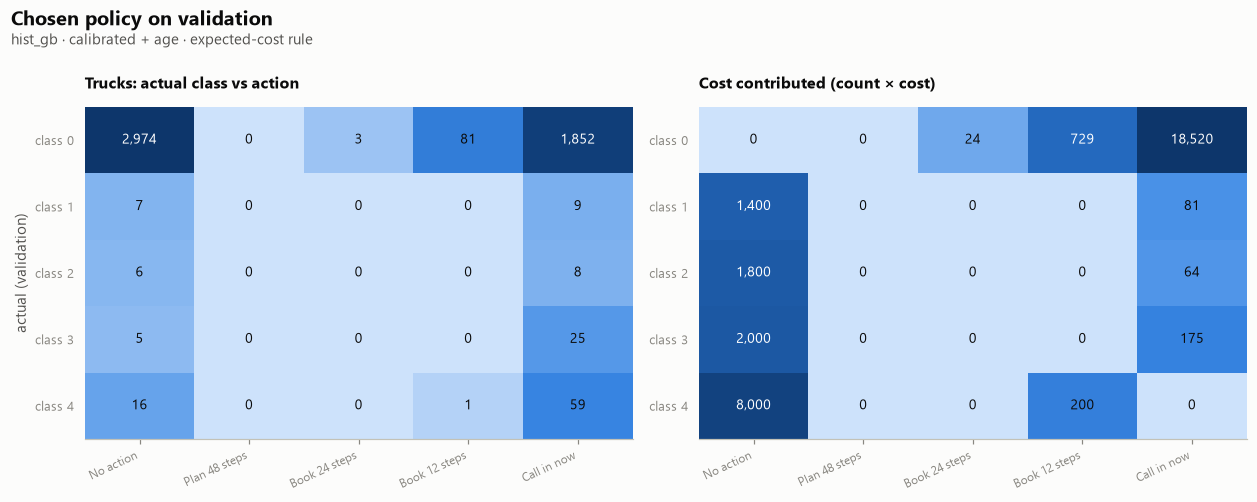

cost from missed/late repairs: 13,400 (41%); from early/unnecessary call-ins: 19,593 (59%)


In [11]:
cm = confusion_matrix(y_val, pred_best, labels=CLASSES)
cost_cells = cm * COST
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for ax, mat, title, fmt in [(axes[0], cm, "Trucks: actual class vs action", "{:,.0f}"),
                            (axes[1], cost_cells, "Cost contributed (count × cost)", "{:,.0f}")]:
    ax.imshow(np.log1p(mat), cmap=viz.blue_cmap(), aspect="auto")
    for i in range(5):
        for j in range(5):
            v = mat[i, j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9,
                    color="#ffffff" if np.log1p(v) > np.log1p(mat).max() * 0.6 else viz.INK)
    ax.set_xticks(CLASSES, [ACTIONS[k].replace("Book within ", "Book ").replace("Plan within ", "Plan ") for k in CLASSES],
                  rotation=25, ha="right", fontsize=8)
    ax.set_yticks(CLASSES, [f"class {k}" for k in CLASSES], fontsize=8.5)
    ax.grid(False)
    ax.set_title(title, fontsize=10.5)
axes[0].set_ylabel("actual (validation)")
viz.suptitle(fig, "Chosen policy on validation", f"{CHOSEN[0]} · {CHOSEN[1]} · expected-cost rule")
fig.tight_layout()
viz.save(fig, "03_confusion", FIGS)
plt.show()
missed = cost_cells[np.tril_indices(5, -1)].sum()
early = cost_cells[np.triu_indices(5, 1)].sum()
print(f"cost from missed/late repairs: {missed:,.0f} ({missed / cost_cells.sum():.0%}); "
      f"from early/unnecessary call-ins: {early:,.0f} ({early / cost_cells.sum():.0%})")

**Interpretation.** The policy calls in 2,040 of 5,046 trucks (404 per 1,000) and catches **102 of the 136 trucks with a repair due (75%)**, including 59 of the 76 that are most urgent (class 4). The remaining cost is split 41% **missed repairs** (34 trucks, of which 16 are class 4 at 500 each, 13,400 in total) and 59% **unnecessary call-ins** (1,852 healthy trucks called in at 10 each, plus 84 booked early). This is the trade-off the cost matrix asks for: about 18 unnecessary call-ins for every repair caught. Cutting it further needs a sharper ranking: the AUC of P(due) on validation is 0.74.

## 8. What drives the risk score (SHAP)

**Choice.** SHAP values explain the quantity the planner acts on: the chosen model's
**log-odds of a repair being due within 48 steps**, *after* recalibration, so the age terms of the
calibrator are included. The permutation explainer is model-agnostic and additive for exactly that
quantity. (The tree explainer would explain the raw per-class margins, which don't add up to P(due).)
To keep the run time reasonable it explains 1,000 validation trucks (all 136 with a repair due plus
864 drawn at random), against a background of 50 random validation trucks. Features are named as
anonymized variables ("counter 427, rate over last 5 readouts"), with no physical meaning implied.

In [12]:
final_params = np.array(calibrators[CHOSEN]) if CHOSEN[1] != "raw" else None
age_terms = CHOSEN[1] == "calibrated + age"


def risk_log_odds(M):
    p = final[CHOSEN[0]].predict_proba(M)
    if final_params is not None:
        p = apply_calibrator(np.log(np.clip(p, 1e-9, 1)), M[:, AGE_IDX], final_params, age_terms)
    return due_log_odds(p)


rng = np.random.default_rng(SEED)
due_idx = np.flatnonzero(y_val > 0)
other_idx = rng.choice(np.flatnonzero(y_val == 0), 1000 - len(due_idx), replace=False)
explain_idx = np.r_[due_idx, other_idx]
background = X_val[rng.choice(len(X_val), 50, replace=False)]
t0 = time.time()
explainer = shap.PermutationExplainer(risk_log_odds, shap.maskers.Independent(background, max_samples=50))
sv = explainer(X_val[explain_idx], max_evals=2 * X_val.shape[1] + 1, silent=True)
print(f"SHAP for {len(explain_idx):,} trucks in {time.time() - t0:,.0f} s")
names = [pretty(f) for f in INPUTS]
importance = pd.DataFrame({"feature": INPUTS, "name": names,
                           "mean_abs_shap": np.abs(sv.values).mean(axis=0)}).sort_values("mean_abs_shap", ascending=False)
importance.head(15)

SHAP for 1,000 trucks in 910 s


,feature,name,mean_abs_shap
0,time_step,age (time_step),0.6226
87,Spec_7,Spec 7,0.2202
81,Spec_1,Spec 1,0.2095
5,c666_level,"counter 666, level",0.1699
45,h167_mean_bin,"histogram 167, mean bin (lifetime)",0.1597
54,h291_top2_share,"histogram 291, share in top 2 bins (lifetime)",0.1407
8,c309_level,"counter 309, level",0.1363
7,c837_level,"counter 837, level",0.1309
11,c100_level,"counter 100, level",0.1244
68,h167_recent5_mean_bin,"histogram 167, mean bin (last 5 readouts)",0.0918


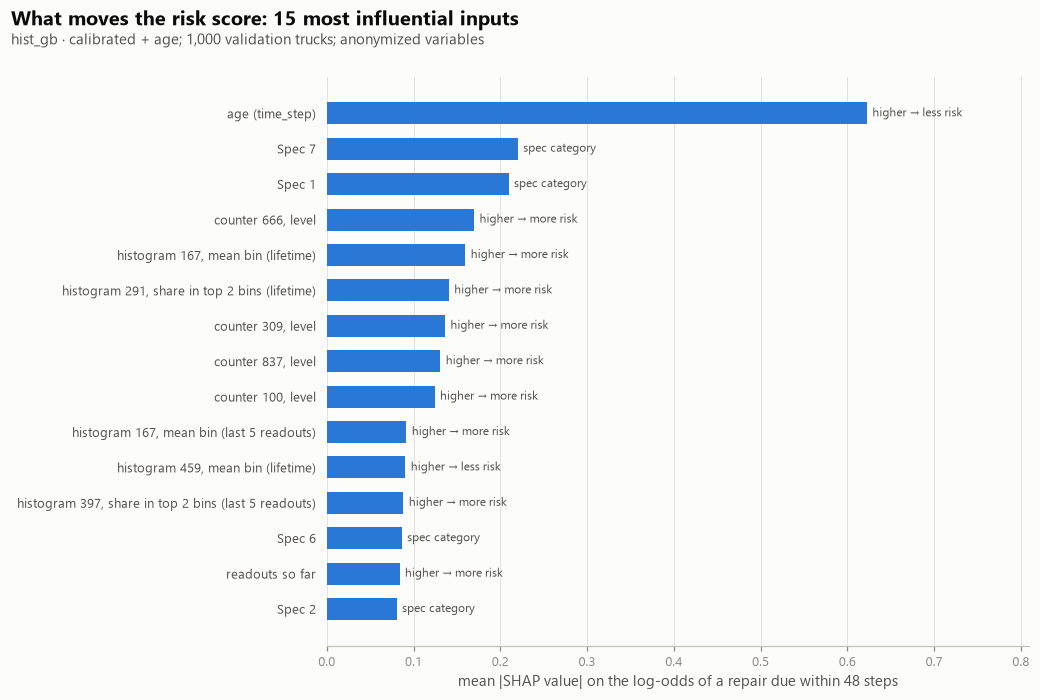

In [13]:
top = importance.head(15).iloc[::-1]
vals = pd.DataFrame(sv.values, columns=INPUTS)
# direction: correlation between a feature's value and its SHAP value (+ = higher value, higher risk)
direction = {f: np.corrcoef(np.nan_to_num(X_val[explain_idx, INPUTS.index(f)]), vals[f])[0, 1]
             if np.nanstd(X_val[explain_idx, INPUTS.index(f)]) > 0 else 0 for f in top.feature}
fig, ax = plt.subplots(figsize=(9.5, 6.2))
ax.barh(range(len(top)), top.mean_abs_shap, color=viz.BLUE, height=0.62)
for i, (f, v) in enumerate(zip(top.feature, top.mean_abs_shap)):
    d = direction[f]
    tag = "spec category" if f.startswith("Spec_") else ("higher → more risk" if d > 0.2 else "higher → less risk" if d < -0.2 else "mixed")
    ax.text(v + top.mean_abs_shap.max() * 0.01, i, tag, va="center", fontsize=8, color=viz.INK2)
ax.set_yticks(range(len(top)), top.name)
ax.tick_params(axis="y", colors=viz.INK2, labelsize=8.5)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, top.mean_abs_shap.max() * 1.3)
ax.set_xlabel("mean |SHAP value| on the log-odds of a repair due within 48 steps")
viz.suptitle(fig, "What moves the risk score: 15 most influential inputs",
             f"{CHOSEN[0]} · {CHOSEN[1]}; 1,000 validation trucks; anonymized variables")
fig.tight_layout()
viz.save(fig, "03_shap_importance", FIGS)
plt.show()

**Interpretation.**

- **Age is the strongest driver** (mean |SHAP| 0.62, about 3× the next input), and on validation older trucks get *lower* risk. That direction comes mostly from the age terms the calibrator learned on validation (notebook 02: validation's due share falls beyond age 250); training alone would push the other way.
- **Specs come next:** Spec 7 and Spec 1, then Spec 6 and Spec 2, consistent with the log-rank and Cox results in notebook 02.
- **Lifetime usage levels:** counters 666, 309, 837 and 100, and the lifetime summaries of histograms 167 and 291. Higher values go with higher risk, matching notebook 01's finding that heavier-used trucks fail more.
- **Recent-window features** (histogram 167 recent mean bin, histogram 397 recent top-2 share) contribute, but less, as expected from the weak timing signal found in notebook 01.

SHAP describes how the model uses its inputs, not causes. With anonymized variables, the drivers are reported as "counter 666, level", not given a physical meaning.

## 9. Saved outputs (for notebook 04 and Power BI)

- `data/processed/validation_scores.csv`: per validation truck, the chosen model's cross-fitted
  class probabilities, expected cost of each action, recommended action, and actual class.
- `data/processed/validation_drivers.csv`: top 3 SHAP drivers for the 1,000 explained trucks.
- `data/processed/shap_importance.csv`, `data/processed/model_comparison_validation.csv`.
- `data/processed/risk_model.joblib` (git-ignored): both fitted models, spec pooling and the final
  calibrators (fitted on all validation trucks), so notebook 04 can score test once.
- `data/processed/risk_model_meta.json`: the frozen choices in readable form.

In [14]:
exp_cost = p_best @ COST
scores = pd.DataFrame({"vehicle_id": val.vehicle_id, "time_step": age_val, "actual_class": y_val,
                       **{f"p{k}": p_best[:, k] for k in CLASSES},
                       **{f"expected_cost_action_{k}": exp_cost[:, k] for k in CLASSES},
                       "recommended_action": pred_best,
                       "recommended_label": [ACTIONS[a] for a in pred_best]})
scores.round(6).to_csv(PROCESSED / "validation_scores.csv", index=False)

rows = []
for i, vid in enumerate(val.vehicle_id.to_numpy()[explain_idx]):
    order = np.argsort(-np.abs(sv.values[i]))[:3]
    row = {"vehicle_id": vid, "risk_log_odds": float(risk_log_odds(X_val[explain_idx[i]:explain_idx[i] + 1])[0])}
    for r, j in enumerate(order, 1):
        row[f"driver_{r}"] = names[j]
        row[f"driver_{r}_shap"] = float(sv.values[i, j])
    rows.append(row)
pd.DataFrame(rows).round(4).to_csv(PROCESSED / "validation_drivers.csv", index=False)
importance.round(5).to_csv(PROCESSED / "shap_importance.csv", index=False)
comparison.round(5).to_csv(PROCESSED / "model_comparison_validation.csv", index=False)

joblib.dump({"models": final, "spec_levels": spec_levels, "inputs": INPUTS,
             "calibrators": {f"{m}|{v}": p for (m, v), p in calibrators.items()},
             "chosen": list(CHOSEN)}, PROCESSED / "risk_model.joblib")
meta = {
    "chosen_model": CHOSEN[0], "chosen_probabilities": CHOSEN[1], "decision_rule": "expected cost",
    "validation_cost_per_1000_crossfitted": round(float(chosen.cost_per_1000), 1),
    "hyperparameters": {"logistic_C": float(best["logistic"].config), "hist_gb_leaves_lr_iters": best["hist_gb"].config},
    "class_weights": cw, "training_points": int(len(train)), "points_per_vehicle_max": K, "seed": SEED,
    "calibrators_fitted_on_all_validation": {f"{m}|{v}": [round(x, 6) for x in p] for (m, v), p in calibrators.items()},
}
(PROCESSED / "risk_model_meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
print("saved:", ", ".join(sorted(p.name for p in PROCESSED.glob("*") if p.stem.startswith(("validation_", "shap_", "model_", "risk_")))))

saved: model_comparison_validation.csv, risk_model.joblib, risk_model_meta.json, shap_importance.csv, validation_drivers.csv, validation_scores.csv


## 10. Findings and what notebook 04 freezes

1. **The risk model cuts the cost of Component X repairs by a third.** Gradient boosting with age-aware calibration and the expected-cost rule costs **6,538 per 1,000 trucks** on validation, against 9,823 for calling everyone in, 9,702 for the fixed-age rule (b), and 8,109 for the validation-tuned age bands. It calls in 40% of trucks and catches 75% of repairs that are due.

2. **Probabilities, calibrated and fed into the cost matrix, matter more than the classifier.** Recalibration alone cuts gradient boosting's cost by 27% (8,955 → 6,538). Picking the most likely class is worse than calling every truck in. In practice the decision is binary (call in now or not); the intermediate booking windows are not worth using under this cost matrix.

3. **The main risk for test is the age correction.** The largest single driver is age, in the direction validation shows (older → less often due) and against training's wear-out pattern. Test was built the same way as validation, so this should carry over, but it is a validation-learned adjustment.

**Frozen for notebook 04:** gradient boosting (31 leaves, learning rate 0.1, 150 iterations, sqrt-balanced class weights), the *calibrated + age* calibrator fitted on all validation trucks, and the expected-cost rule. These are saved in `data/processed/risk_model.joblib` and `risk_model_meta.json`. Notebook 04 evaluates this policy once on test. As a declared secondary check, it also reports the *calibrated* (no age) variant, so the size of the age effect on test is visible.

In [15]:
con.close()